In [1]:
import os
import sys

import joblib
import itertools
import pandas as pd
import numpy as np
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..')
from utils.plotting import plot_movement_data
from utils.metrics import movement_level_confusion
from utils.helper_functions import load_outlier_data
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.ocsvm_detector import OCSVMDetector
from utils.helper_functions import calculate_trash_percentage
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Pick'
ALGORITHM_NAME = 'OCSVM'
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [3]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)
print(f"Number of movements: {n_movements}")

Number of movements: 380


In [4]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
GT L: 2 positivos / 380 movimentos = 0.53%
GT R: 2 positivos / 380 movimentos = 0.53%
GT OR: 3 positivos / 380 movimentos = 0.79%


### Load Features from csv

In [ ]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()
n_movements_f = len(features_df)
total_trials = features_df.drop_duplicates(subset=['sub', 'repID']).shape[0]

assert not np.isnan(X_features).any(), "NaN in features"
assert len(features_df) == n_movements, (len(features_df), n_movements)
assert set(map(tuple, features_df[Configs.KEYS].values)) == base_keys
print(X_features.shape)

## One Class SVM With Feature Extraction

In [6]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

# Ground truth used for evalution on this run
GT_KEY = 'OR'  # TODO isto vai ter de ficar noutro local, mas por agora é só para testar
gt_used = GT[GT_KEY]
total_known_outliers = len(gt_used)

# Movement-level anomalies
known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
known_percentage = known_outlier_rate * 100

# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")
print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")

Phase: Pick
positives by ground truth: {'L': 2, 'R': 2, 'OR': 3}
GT used (Union): 3 positives / 380 movements = 0.79%


### Grid Search

In [ ]:
min_nu = 0.01 
max_nu = known_outlier_rate + 0.10            
nu_range = np.linspace(min_nu, max_nu, 15)
nu_range = [round(n, 3) for n in nu_range] 

gamma_options = ['scale', 'auto', 0.01, 0.1, 1] 
results_log = []

param_grid = [
    {'nu': n, 'gamma': g} 
    for n, g in itertools.product(nu_range, gamma_options)
]

loso_results = run_loso_evaluation(
    detector_class=OCSVMDetector, 
    param_grid=param_grid,
    data_matrix=X_features,
    metadata_df=features_df[Configs.META_COLS],
    known_outliers_df=gt_used,
    metric_type='euclidean',
    scale_features=True,
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

LOSO Cross-Validation with 19 subjects (3 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Statistic Evaluation - Bootstraping

In [8]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [9]:
append_experiment_record(
    summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, GT_KEY),
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=n_movements,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for OCSVM - FeatureBased - Pick - 380 Movements (MOVEMENT-level):
Unique Outliers Detected: 37
Rejection Rate: 9.74%
Known Positives in Ground Truth: 3
------------------------------
Total True Positives (Global):  2
Total False Positives (Global): 35
Total False Negatives (Global): 1
Total True Negatives (Global):  342
------------------------------
Blind Precision: 5.41 [0.00–12.30]
Blind Recall:    66.67 [0.00–100.00]
Blind F1-Score:  10.00
Blind F2-Score:  20.41 [0.00–39.22]
Blind MCC:       0.17 [-0.02–0.32]
Blind AUPRC:  37.28 [0.68–100.00]
Blind AUROC:   84.35

Total Tuning Time (19 Subjects): 16.5292s
Total Inference Time (19 Subjects): 0.0139s

Overall Best Parameters (Most frequent across folds):
   {'gamma': 0.01, 'nu': np.float64(0.031)}
Occurrences: 5


## Train Final Model

In [ ]:
best_params = loso_results['Best_Params']
nu = best_params['nu']
gamma = best_params['gamma']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

Dropped features: ['max_acc', 'max_vel', 'mean_acc', 'path_length', 'vel_skewness', 'wrist_dist_min']


In [11]:
ocsvm_final = OneClassSVM(kernel='rbf', nu=best_params['nu'], gamma=best_params['gamma'])

# Train mode (oultier = -1, normal = 1)
labels = ocsvm_final.fit_predict(X_features_scaled_full)
features_df['anomaly'] = labels
joblib.dump(ocsvm_final, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# Results
n_outliers = (features_df['anomaly'] == -1).sum()
outliers_details = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

n_unique_outliers, correct_trash_pct = calculate_trash_percentage(features_df, total_trials)
print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/total_trials*100):.2f}%")
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 16
Unique Outlier Trials Detected: 15
Detected Outlier Percentage (sub + repID + movID): 16.84%
Detected Outlier Percentage (sub + repID): 15.79%


In [12]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outliers_details.index, cols_to_extract].copy()
print("Outliers metadata:")
print(outliers_metadata_df)

Outliers metadata:
     sub  repID  movID
48     3      3      1
104    6      2      1
121    7      1      3
137    7      5      3
144    8      2      1
186   10      2      5
250   13      3      5
256   13      5      1
259   13      5      7
279   14      5      7
283   15      1      7
300   16      1      1
305   16      2      3
338   17      5      5
354   18      4      5
356   18      5      1


In [13]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = movement_level_confusion(features_df, np.where(labels == -1)[0], gt_used, Configs.KEYS)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 1
False Positives (Identified, not in CSV): 14
False Negatives (In CSV, not identified): 2
True Negatives (Normal, stayed normal): 78
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
0   13      1
2    3      5

Precision (False Positives): 1/15 (6.67%)
Recall (True Positive Rate): 1/3 (33.33%)
F1-Score: 11.11%
F2-Score: 18.52%


O código abaixo serve para criar as variáveis que existiam antes do refactor para cirar os gráficos. Não quero mexer muito na forma como os gráficos são montados para evitar problemas.

In [14]:
outlier_ids = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['anomaly'] == -1]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; it does not permanently alter the original df if you do not want it to
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]


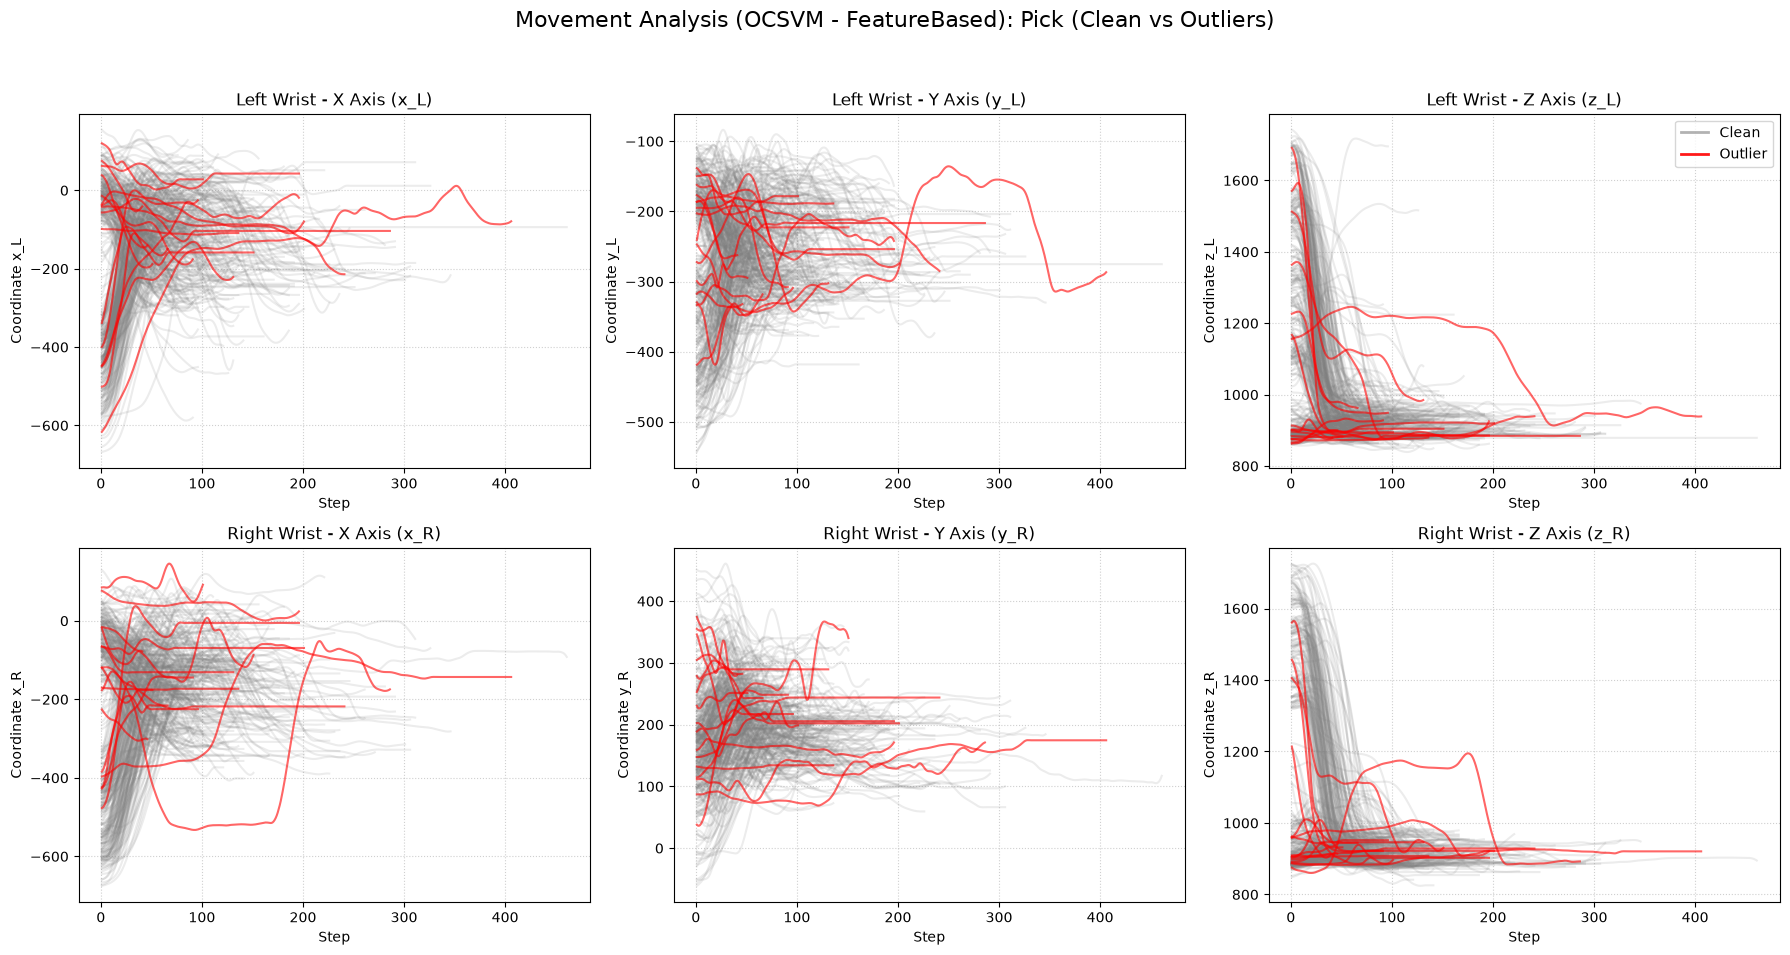

In [15]:
plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

In [16]:
df.drop(columns=['temp_key'], inplace=True)